<a href="https://colab.research.google.com/github/ThembaMapundu/MMA3001-Project/blob/main/notebooks/CO2_Data_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

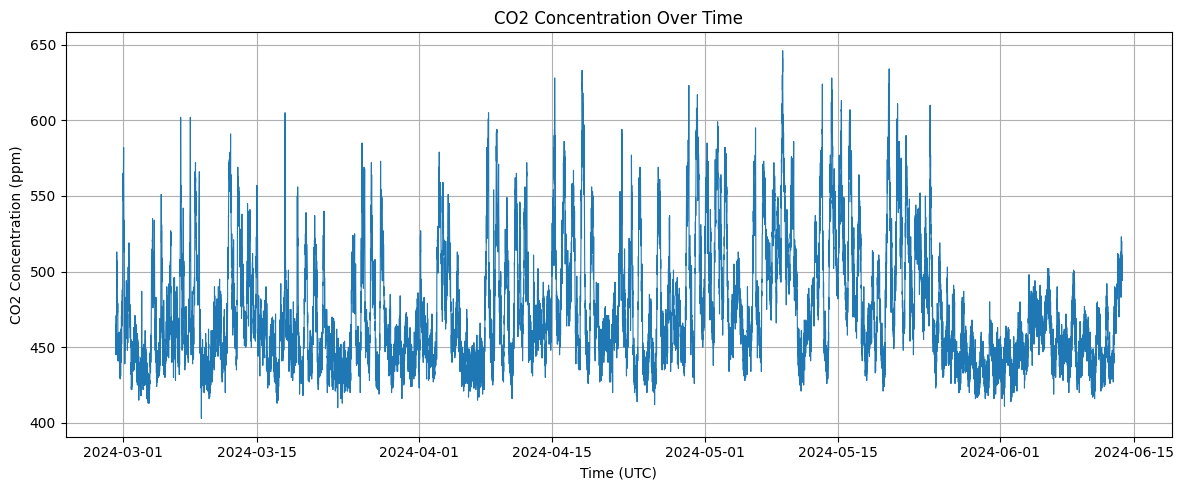

In [17]:


# CO2 DATA ANALYSIS FOR CONCENTRATION WITHIN THE OBSERVATION PERIOD

# Import dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#IMPORT DATA FROM GITHUB REPO
# Construct the raw GitHub URL
url = (f"https://raw.githubusercontent.com/ThembaMapundu/MMA3001-Project/main/SourceData/co2_clean.xlsx")

# Import Excel dataset from the url
data = pd.read_excel(url, engine="openpyxl")

# Select sensor, sensor with the most frequent readings
sensor_id = 6012002000869

# Filter data
sensor_data = data[data["sensor_id"] == sensor_id].copy()

# Convert timestamps
sensor_data["timestamp_utc"] = pd.to_datetime(sensor_data["timestamp_utc"],utc=True)

# Extract NumPy arrays
time = sensor_data["timestamp_utc"].dt.tz_localize(None).to_numpy()
co2 = sensor_data["co2_ppm"].to_numpy(dtype=float)

# Remove invalid observations (data with no time, data that is not a number and data that is less than 0)
valid = (~np.isnat(time)) & np.isfinite(co2) & (co2 > 0)

time = time[valid]
co2 = co2[valid]

# Sort by time
order = np.argsort(time)
time = time[order]
co2 = co2[order]

#print the results
#first plot, how CO2 changes across an observation period

plt.figure(figsize=(12, 5))
plt.plot(time, co2, linewidth=0.8)
plt.xlabel("Time (UTC)")
plt.ylabel("CO2 Concentration (ppm)")
plt.title("CO2 Concentration Over Time")
plt.grid()
plt.tight_layout()
plt.show()


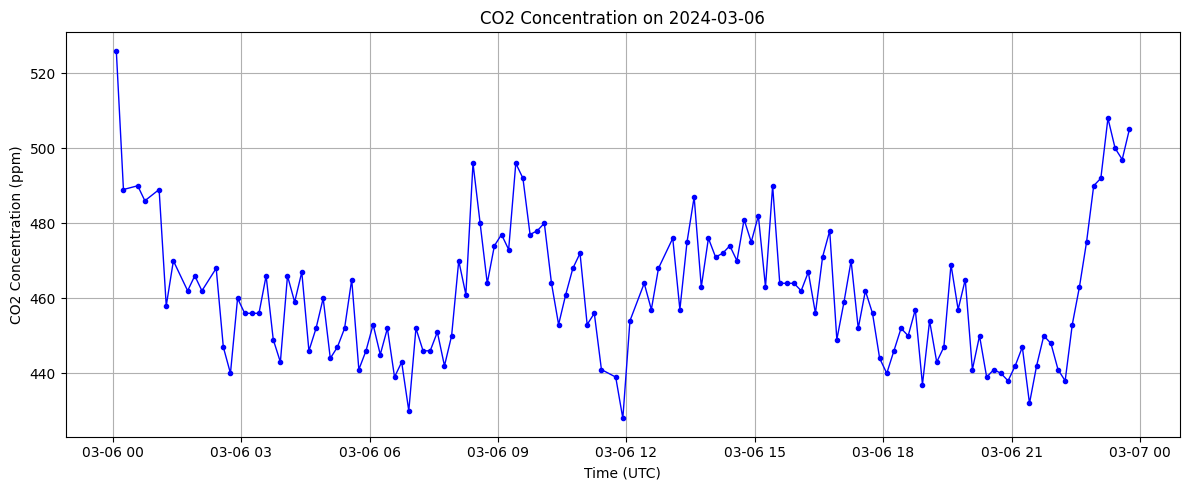

Selected day: 2024-03-06
Number of measurements: 136
Minimum CO2: 428.0 ppm
Maximum CO2: 526.0 ppm


In [18]:
# CO2 DATA ANALYSIS FOR CONCENTRATION WITHIN A DAY

# Convert timestamps into dates (remove time of day)
days = time.astype("datetime64[D]")

# Find all available dates and count observations
unique_days, counts = np.unique(days, return_counts=True)

# Select the day with the most measurements
selected_day = unique_days[np.argmax(counts)]

# Select measurements recorded on that day
day_mask = days == selected_day

day_time = time[day_mask]
day_co2 = co2[day_mask]

# Plot CO2 concentration against time
plt.figure(figsize=(12, 5))

plt.plot(day_time,day_co2,marker="o",markersize=3,linewidth=1,color="blue")
plt.xlabel("Time (UTC)")
plt.ylabel("CO2 Concentration (ppm)")
plt.title(f"CO2 Concentration on {selected_day}")
plt.grid()
plt.tight_layout()
plt.show()

# Display information about selected day
print("Selected day:", selected_day)
print("Number of measurements:", len(day_co2))
print("Minimum CO2:", np.min(day_co2), "ppm")
print("Maximum CO2:", np.max(day_co2), "ppm")



SAMPLING INTERVAL ANALYSIS
----------------------------
Minimum interval: 9.57 min
Maximum interval: 29.98 min
Mean interval: 11.01 min
Median interval: 10.00 min
Intervals > 20 min: 259


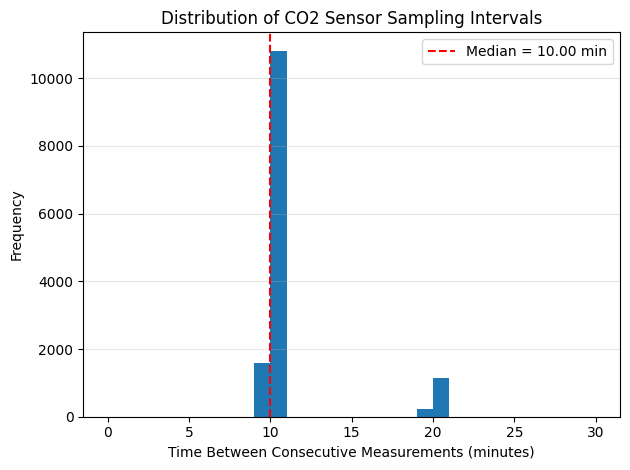

In [19]:

# MMA3001 - Graph 3: Distribution of Sampling Intervals
# Step 1: Calculate the difference between timestamps
time_diff = np.diff(time)

# Step 2: Convert time differences into minutes
intervals = time_diff / np.timedelta64(1, "m")

# Step 3: Calculate sampling interval statistics
median_interval = np.median(intervals)
mean_interval = np.mean(intervals)
min_interval = np.min(intervals)
max_interval = np.max(intervals)

# Step 4: Identify intervals longer than expected
long_intervals = np.sum(intervals > 20)

# Display results
print("SAMPLING INTERVAL ANALYSIS")
print(f"Minimum interval: {min_interval:.2f} min")
print(f"Maximum interval: {max_interval:.2f} min")
print(f"Mean interval: {mean_interval:.2f} min")
print(f"Median interval: {median_interval:.2f} min")
print(f"Intervals > 20 min: {long_intervals}")

# Step 5: Plot the distribution
plt.figure()

plt.hist(intervals,bins=np.arange(0, 31, 1))

# Reference line showing the median interval
plt.axvline(median_interval,color="red",linestyle="--",label=f"Median = {median_interval:.2f} min")

plt.xlabel("Time Between Consecutive Measurements (minutes)")
plt.ylabel("Frequency")
plt.title("Distribution of CO2 Sensor Sampling Intervals")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
